In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core

from optim_utils import set_params
from hnn_core.dipole import _rmse
from hnn_core.params import _short_name

from hnn_core import duecker_2025_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/users/kduecker/hnn-tuning/new_model_HNN/figures/detect_vs_nondetect'

# The number of cores may need modifying depending on your current machine.
n_procs = 10

plt.rcParams['svg.fonttype'] = 'none'
# Set global font sizes
plt.rcParams['font.size'] = 16          # Default text size
plt.rcParams['axes.titlesize'] = 16      # Title size
plt.rcParams['axes.labelsize'] = 16      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 16    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 16     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 16     # Legend text


--No graphics will be displayed.


In [2]:
yes_dpl = read_dipole('/users/kduecker/hnn-tuning/hnn-data/MEG_detection_data/yes_trial_S1_ERP_all_avg.txt')
no_dpl = read_dipole('/users/kduecker/hnn-tuning/hnn-data/MEG_detection_data/no_trial_S1_ERP_all_avg.txt')

In [3]:
# load supra as starting point
import pickle
from optimize_drives_slurm import set_params, set_params_time

with open('optim_time_scale_1000.pkl', 'rb') as file:
        net_supra = pickle.load(file)

net_supra = net_supra.net_

In [4]:
tstop = yes_dpl.times[-1]

In [5]:
supra_dpl = simulate_dipole(net_supra, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]

scale_factor = 1000
smooth_window_len = 5

supra_dpl.smooth(smooth_window_len).scale(scale_factor)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /oscar/home/kduecker/hnn-tuning/local_hnn/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Applying calcium model baseline correction


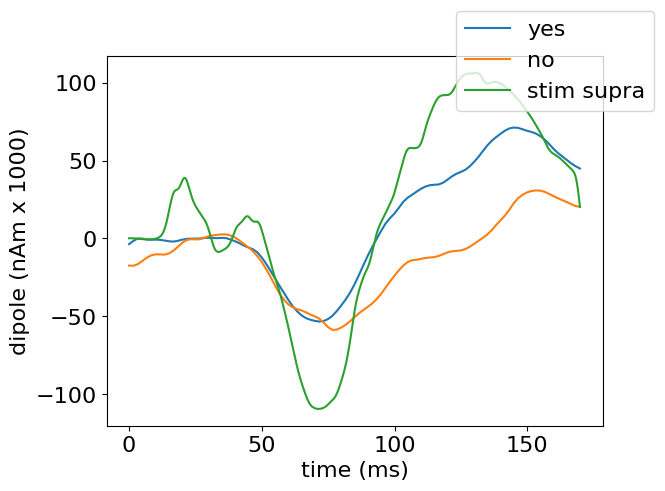

In [6]:
fig, ax = plt.subplots()
ax.plot(yes_dpl.times, yes_dpl.data['agg'], label='yes')
ax.plot(no_dpl.times, no_dpl.data['agg'], label='no')
ax.plot(supra_dpl.times, supra_dpl.data['agg'], label='stim supra')
ax.set_ylabel('dipole (nAm x 1000)')
ax.set_xlabel('time (ms)')
fig.legend()



In [7]:
prox1 = dict()
prox1['mu'] = net_supra.external_drives['prox1']['dynamics']['mu']
prox1['sigma'] = net_supra.external_drives['prox1']['dynamics']['sigma']
prox1['numspikes'] = net_supra.external_drives['prox1']['dynamics']['numspikes']
prox1['weights_ampa'] = net_supra.external_drives['prox1']['weights_ampa']
prox1['weights_nmda'] = net_supra.external_drives['prox1']['weights_nmda']
evdist = dict()
evdist['mu'] = net_supra.external_drives['dist']['dynamics']['mu']
evdist['sigma'] = net_supra.external_drives['dist']['dynamics']['sigma']
evdist['numspikes'] = net_supra.external_drives['dist']['dynamics']['numspikes']
evdist['weights_ampa'] = net_supra.external_drives['dist']['weights_ampa']
evdist['weights_nmda'] = net_supra.external_drives['dist']['weights_nmda']
prox2 = dict()    
prox2['mu'] = net_supra.external_drives['prox2']['dynamics']['mu']
prox2['sigma'] = net_supra.external_drives['prox2']['dynamics']['sigma']
prox2['numspikes'] = net_supra.external_drives['prox2']['dynamics']['numspikes']
prox2['weights_ampa'] = net_supra.external_drives['prox2']['weights_ampa']
prox2['weights_nmda'] = net_supra.external_drives['prox2']['weights_nmda']

## Init yes

MPI will run 1 trial(s) sequentially by distributing network neurons over 20 processes.
/users/kduecker/.conda/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/users/kduecker/.conda/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/users/kduecker/.conda/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/users/kduecker/.conda/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/users/kduecker/.conda/envs/local_hnn/bin/nrniv:10: DeprecationWarni

/oscar/home/kduecker/hnn-tuning/local_hnn/hnn_core/parallel_backends.py:475: UserWarning: Failed to kill nrniv process(es) 2251987,2251986,2224359,2224370,2224357,2224360,2224369,2224358,2251978,2224361,2251979,2224353,2224363,2251980,2251983,2224355,2224367,2251981,2224362,2224365,2224352,2251982,2224366,2224364,2224356,2251984,2224354,2224368,2251985
  warn("Failed to kill nrniv process(es) %s" %


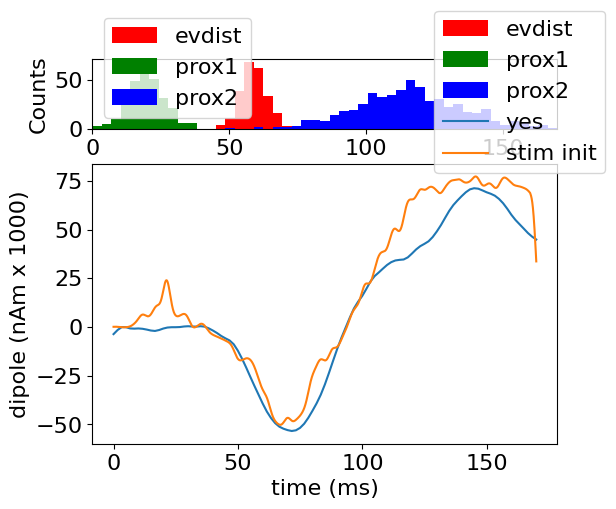

In [9]:
net_init_yes = duecker_2025_ET_model()

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

net_init_yes.add_evoked_drive('prox1',
                        mu=20,
                        sigma=6.5,
                        numspikes=1,
                        location='proximal',
                        weights_ampa={'L2_basket': 0.005,
                                        'L2_pyramidal': 0.1,
                                        'L5_basket': 0.08,
                                        'L5_pyramidal': 0.05},
                        weights_nmda={'L2_basket': 0.009,
                                        'L2_pyramidal': 0.0004,
                                        'L5_basket': 0.015,
                                        'L5_pyramidal': 0.002},
                        synaptic_delays=synaptic_delays_p, event_seed=544)

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init_yes.add_evoked_drive('evdist',
                        mu=59.0,
                        sigma=4.5,
                        numspikes=1,
                        location='distal',
                        weights_ampa={'L2_basket': 0.0045,
                                'L2_pyramidal': 0.001,
                                'L5_pyramidal': 0.03},
                        weights_nmda={'L2_basket': 0.0006,
                                'L2_pyramidal': 0.35,
                                'L5_pyramidal': 0.02},
                        synaptic_delays=synaptic_delays_d, event_seed=544)


net_init_yes.add_evoked_drive('prox2',
                              mu=115,
                              sigma=20,
                              numspikes=2,
                              location='proximal',
                                weights_ampa={'L2_basket': 0.01,
                                        'L2_pyramidal': 0.4,
                                        'L5_basket': 0.009,
                                        'L5_pyramidal': 0.4},
                                weights_nmda={'L2_basket': 0.01,
                                        'L2_pyramidal': 0.07,
                                        'L5_basket': 0.0003,
                                        'L5_pyramidal': 0.5})

with MPIBackend(n_procs=20, mpi_cmd='mpiexec'):
        init_yes = simulate_dipole(net_init_yes, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]
init_yes.smooth(smooth_window_len).scale(scale_factor)

yes_rmse_init = _rmse(yes_dpl, init_yes, tstart=0,tstop=1000)

fig, ax = plt.subplots(2,1, height_ratios=[0.25,1],figsize=(6,5))
net_init_yes.cell_response.plot_spikes_hist(ax=ax[0], show=False)
ax[1].plot(yes_dpl.times, yes_dpl.data['agg'], label='yes')
ax[1].plot(init_yes.times, init_yes.data['agg'], label='stim init')
ax[1].set_ylabel('dipole (nAm x 1000)')
ax[1].set_xlabel('time (ms)')  
fig.legend()

## init no

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

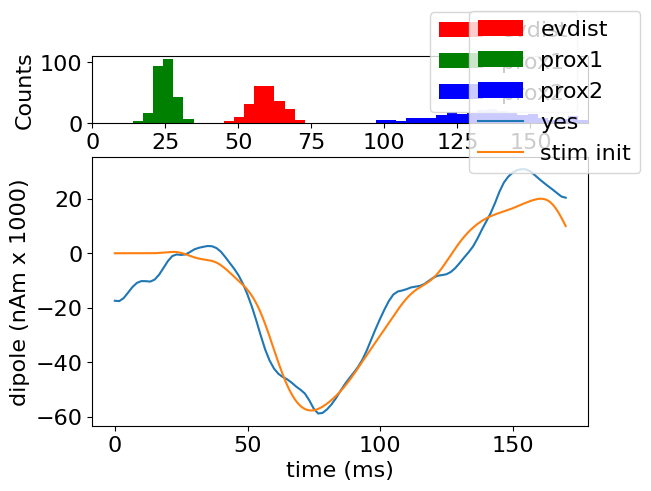

In [ ]:
net_init_no = duecker_2025_ET_model()
smooth_window_len = 20
synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

net_init_no.add_evoked_drive('prox1',
                        mu=25,
                        sigma=3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa={'L2_basket': 0.005,
                                        'L2_pyramidal': 0.02,
                                        'L5_basket': 0.075,
                                        'L5_pyramidal': 0.0043},
                        weights_nmda={'L2_basket': 0.01,
                                        'L2_pyramidal': 0.0003,
                                        'L5_basket': 0.015,
                                        'L5_pyramidal': 0.002},
                        synaptic_delays=synaptic_delays_p, event_seed=544)

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init_no.add_evoked_drive('evdist',
                        mu=60,
                        sigma=5,
                        numspikes=1,
                        location='distal',
                        weights_ampa={'L2_basket': 0.0045,
                                'L2_pyramidal': 0.02,
                                'L5_pyramidal': 0.05},
                        weights_nmda={'L2_basket': 0.00056,
                                'L2_pyramidal': 0.035,
                                'L5_pyramidal': 0.02},
                        synaptic_delays=synaptic_delays_d, event_seed=544)


net_init_no.add_evoked_drive('prox2',
                              mu=135,
                              sigma=20,
                              numspikes=1,
                              location='proximal',
                                weights_ampa={'L2_basket': 0.009,
                                        'L2_pyramidal': 0.015,
                                        'L5_basket': 0.018,
                                        'L5_pyramidal': 0.25},
                                weights_nmda={'L2_basket': 0.009,
                                        'L2_pyramidal': 0.01,
                                        'L5_basket': 0.0006,
                                        'L5_pyramidal': 0.265})

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        init_no = simulate_dipole(net_init_no, tstop=tstop, n_trials=1, bsl_cor='calcium', record_ca='all', record_vsec='all')[0]
init_no.smooth(smooth_window_len).scale(scale_factor)

no_rmse_init = _rmse(no_dpl, init_no, tstart=0,tstop=1000)

fig, ax = plt.subplots(2,1, height_ratios=[0.25,1])
net_init_no.cell_response.plot_spikes_hist(ax=ax[0], show=False)
ax[1].plot(no_dpl.times, no_dpl.data['agg'], label='yes')
ax[1].plot(init_no.times, init_no.data['agg'], label='stim init')
ax[1].set_ylabel('dipole (nAm x 1000)')
ax[1].set_xlabel('time (ms)')  
fig.legend()

## optimization

In [13]:
def set_params_yes(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

    net.add_evoked_drive('prox1',
                        mu=23,
                        sigma=6.5,
                        numspikes=1,
                        location='proximal',
                        weights_ampa={'L2_basket': 0.005,
                                        'L2_pyramidal': 0.027,
                                        'L5_basket': 0.08,
                                        'L5_pyramidal': 0.004},
                        weights_nmda={'L2_basket': 0.009,
                                        'L2_pyramidal': 0.0004,
                                        'L5_basket': 0.015,
                                        'L5_pyramidal': 0.002},
                        synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    
    weights_ampa_d = {'L2_basket':
                       params['dist_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['dist_ampa_L2_pyramidal'],
                       'L5_pyramidal':
                       params['dist_ampa_L5_pyramidal']}
    weights_nmda_d = {'L2_basket':
                       params['dist_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['dist_nmda_L2_pyramidal'],
                       'L5_pyramidal':
                       params['dist_nmda_L5_pyramidal']}
    

    net.add_evoked_drive('dist',
                         mu=59.0,
                         sigma=4.5,
                         numspikes=1,
                         location='distal',
                         weights_ampa=weights_ampa_d,
                         weights_nmda=weights_nmda_d,
                         synaptic_delays=synaptic_delays_d, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['prox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['prox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['prox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['prox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['prox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['prox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['prox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['prox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('prox2',
                        mu=115,
                        sigma=20,
                        numspikes=2,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

constraints = constraints = dict({

                    'dist_ampa_L2_basket': (0.0001, 0.01),
                    'dist_ampa_L2_pyramidal': (0.0005, .01),
                    'dist_ampa_L5_pyramidal': (0.005, .05),

                    'dist_nmda_L2_basket': (0.0001, 0.001),
                    'dist_nmda_L2_pyramidal': (0.01, .6),
                    'dist_nmda_L5_pyramidal': (0.005, .5),

                    'prox2_ampa_L2_basket': (0.005, .05),
                    'prox2_ampa_L2_pyramidal': (0.05, .6),
                    'prox2_ampa_L5_basket': (0.0001, .03),
                    'prox2_ampa_L5_pyramidal': (0.1, .7),

                    'prox2_nmda_L2_basket': (0.001, 0.04),
                    'prox2_nmda_L2_pyramidal': (0.01, 1.),
                    'prox2_nmda_L5_basket': (0.00005, 0.01),
                    'prox2_nmda_L5_pyramidal': (0.1, 1.)})

In [ ]:
max_iter = 200
net = duecker_2025_ET_model()
optim_yes = Optimizer(net, tstop=tstop, constraints=constraints,
                set_params=set_params_yes, solver='bayesian', obj_fun='dipole_rmse', max_iter=max_iter)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_yes.fit(target=yes_dpl, scale_factor=scale_factor,
            smooth_window_len=smooth_window_len, bsl_cor='calcium')

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_yes = simulate_dipole(optim_yes.net_, tstop=tstop, n_trials=1, bsl_cor='calcium')[0]

opt_yes.scale(scale_factor)
opt_yes.smooth(smooth_window_len)

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

Text(150, 30, 'opt RMSE: 4.86')

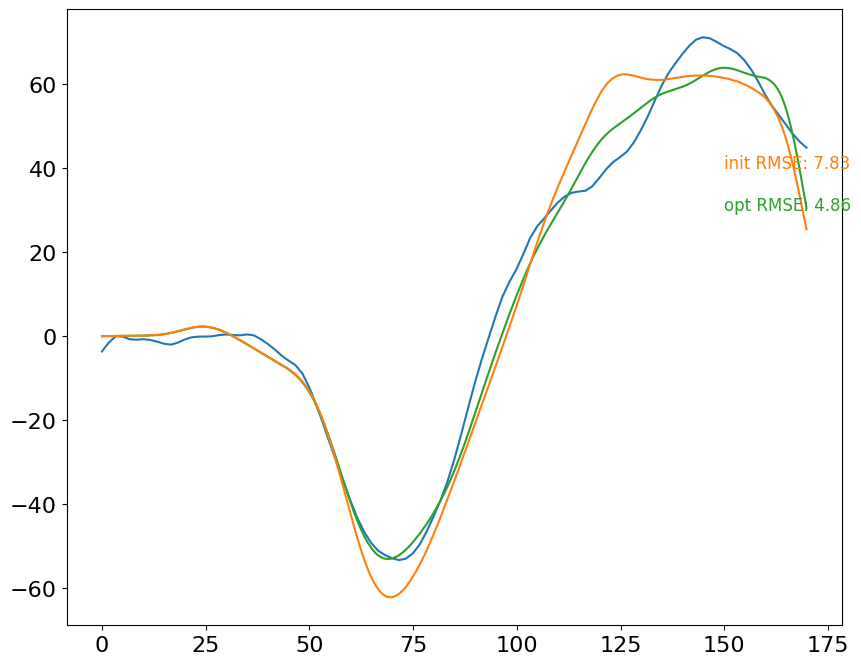

In [17]:
yes_rmse_opt = _rmse(opt_yes, yes_dpl, tstart=0,tstop=1000)
fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(yes_dpl.times, yes_dpl.data['agg'])

ax.plot(opt_yes.times, opt_yes.data['agg'], color='tab:green', label='opt')
ax.plot(init_yes.times, init_yes.data['agg'], color='tab:orange', label='init')

ax.text(150,40, f'init RMSE: {yes_rmse_init:.2f}', fontsize=12, color='tab:orange')
ax.text(150,30, f'opt RMSE: {yes_rmse_opt:.2f}', fontsize=12, color='tab:green')

In [18]:
import pickle

with open('optim_yes.pkl', 'wb') as file:
        pickle.dump(optim_yes, file)

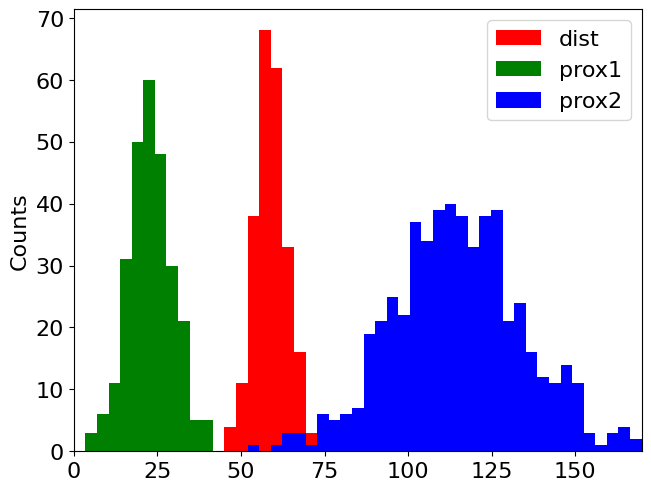

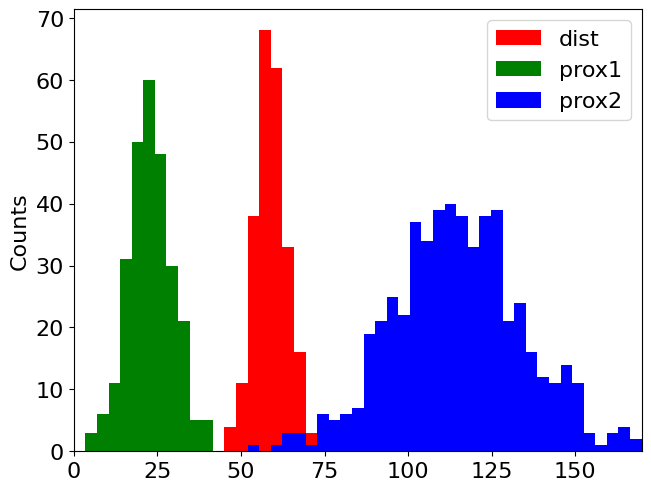

In [16]:
optim_yes.net_.cell_response.plot_spikes_hist()



## old code

In [31]:
yes_l5_tuft = np.zeros((100, len(net_init_yes.cell_response.times)))

for i, gid in enumerate(net_init_yes.gid_ranges['L5_pyramidal']):
    yes_l5_tuft[i] = net_init_yes.cell_response.ca[0][gid]['apical_tuft']

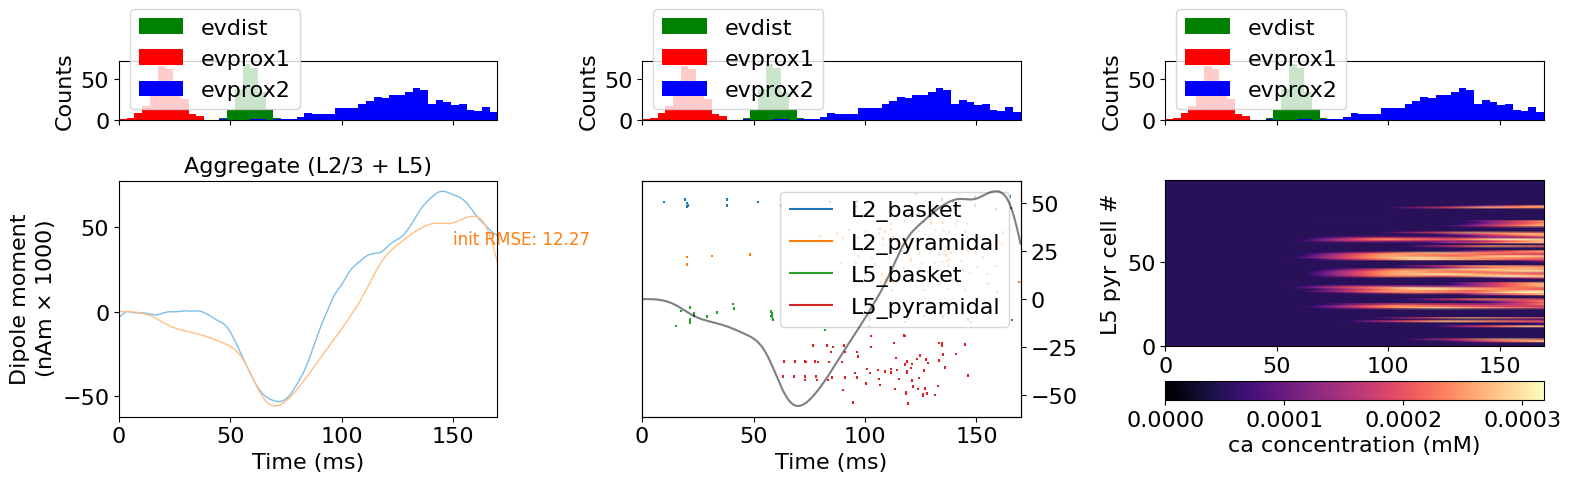

In [ ]:
fig, axes = plt.subplots(2,3,figsize=(16, 5), sharex=True, height_ratios=[0.25,1])

net_init_yes.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_init_yes.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_init_yes.cell_response.plot_spikes_hist(ax=axes[0,2], spike_types=['prox1', 'evdist', 'prox2'], show=False)


yes_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_yes.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,40, f'init RMSE: {yes_rmse_init:.2f}', fontsize=12, color='tab:orange')

net_init_yes.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(init_yes.times,init_yes.data['agg'],color='k', alpha=0.5)

ca_map = axes[1,2].pcolormesh(net_init_yes.cell_response.times, np.arange(100), yes_l5_tuft, cmap='magma', shading='gouraud', vmin=0)
axes[1,2].set_ylabel('L5 pyr cell #')
axes[1,2].set_xlabel('time (ms)')
cb = plt.colorbar(ax=axes[1,2], mappable=ca_map, label='ca concentration (mM)', orientation='horizontal')
cb.set_ticks(np.arange(0,0.0004,0.0001))
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'yes_dpl_init.png'))

In [ ]:
def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
    net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0

    return net_no_ca

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...


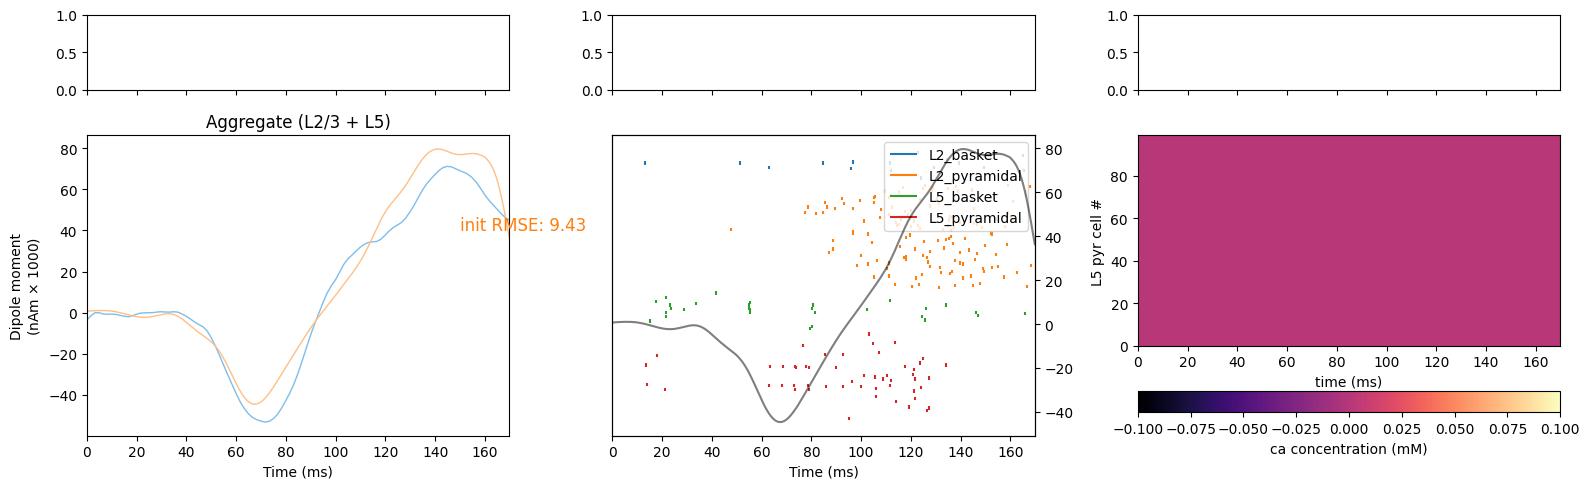

In [ ]:
net_init_yes_off = net_init_yes.copy()

net_init_yes_off = net_block_ca(net_init_yes_off)
yes_l5_tuft_off = np.zeros((100, len(net_init_yes_off.cell_response.times)))

for i, gid in enumerate(net_init_yes.gid_ranges['L5_pyramidal']):
    yes_l5_tuft[i] = net_init_yes_off.cell_response.ca[0][gid]['apical_tuft']

dpl_ca_off = simulate_dipole(net_init_yes_off, tstop=tstop, n_trials=1, bsl_cor='calcium', record_ca='all', record_vsec='all')[0]
dpl_ca_off.smooth(smooth_window_len).scale(scale_factor)

yes_rmse_off = _rmse(yes_dpl, dpl_ca_off, tstart=0,tstop=1000)
fig, axes = plt.subplots(2,3,figsize=(16, 5), sharex=True, height_ratios=[0.25,1])

# net_init_yes_off.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['prox1', 'evdist', 'prox2'], show=False)
# net_init_yes_off.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['prox1', 'evdist', 'prox2'], show=False)
# net_init_yes_off.cell_response.plot_spikes_hist(ax=axes[0,2], spike_types=['prox1', 'evdist', 'prox2'], show=False)


yes_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
dpl_ca_off.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,40, f'init RMSE: {yes_rmse_off:.2f}', fontsize=12, color='tab:orange')

net_init_yes_off.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(init_yes.times,dpl_ca_off.data['agg'],color='k', alpha=0.5)

ca_map = axes[1,2].pcolormesh(net_init_yes_off.cell_response.times, np.arange(100), yes_l5_tuft_off, cmap='magma', shading='gouraud', vmin=0)
axes[1,2].set_ylabel('L5 pyr cell #')
axes[1,2].set_xlabel('time (ms)')
cb = plt.colorbar(ax=axes[1,2], mappable=ca_map, label='ca concentration (mM)', orientation='horizontal')
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'yes_dpl_ca_off.png'))

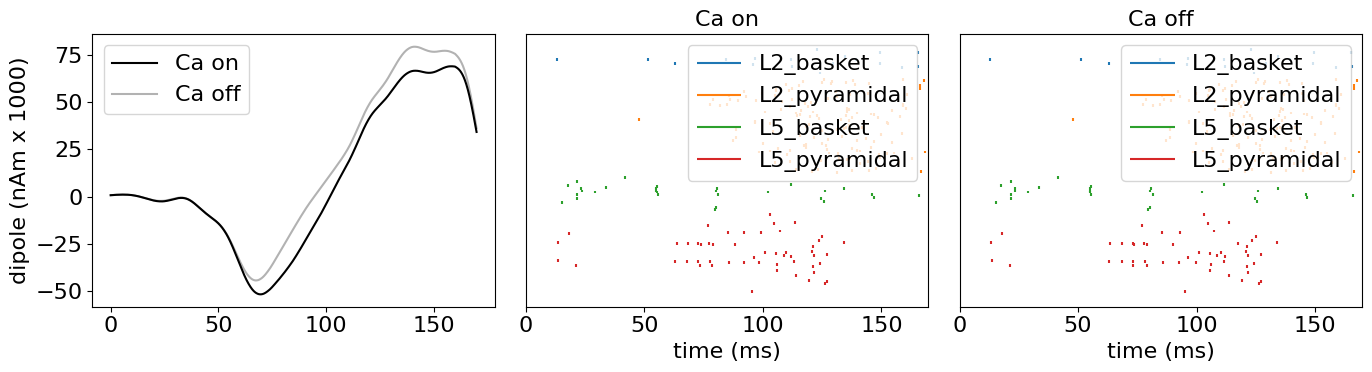

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(14,4))


ax[0].plot(init_yes.times,init_yes.data['agg'],color='k', label='Ca on')
ax[0].plot(init_yes.times,dpl_ca_off.data['agg'],color='k', alpha=0.3, label='Ca off')
ax[0].set_ylabel('dipole (nAm x 1000)')
ax[0].legend()

ax2.set_ylim(-60, 100)

net_init_yes.cell_response.plot_spikes_raster(ax=ax[1], show=False)

ax[1].set_title('Ca on')
ax[1].set_ylabel('cell #')
ax[1].set_xlabel('time (ms)')

net_init_yes_off.cell_response.plot_spikes_raster(ax=ax[2], show=False)

ax[2].set_title('Ca off')

ax[2].set_ylabel('cell #')
ax[2].set_xlabel('time (ms)')

fig.tight_layout()

fig.savefig(os.path.join(pathfig,'ca_on_vs_off_dpl_spiking.png'))
fig.savefig(os.path.join(pathfig,'ca_on_vs_off_dpl_spiking.svg'))

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...


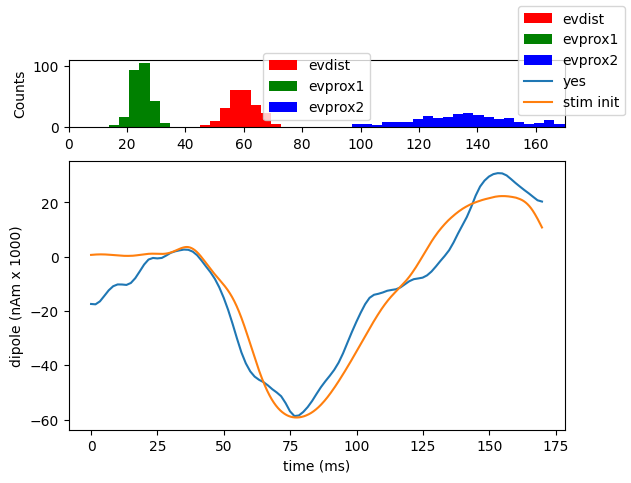

In [ ]:
net_init_no = duecker_2025_ET_model()
smooth_window_len = 20
synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

net_init_no.add_evoked_drive('prox1',
                        mu=25,
                        sigma=3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa={'L2_basket': 0.049215652055858136*0.01,
                                        'L2_pyramidal': 0.008739791084703059*0.1,
                                        'L5_basket': 0.07533928398974252,
                                        'L5_pyramidal': 0.43358890188330773*0.1},
                        weights_nmda={'L2_basket': 0.09377367973932317*0.01,
                                        'L2_pyramidal': 0.002633168778091414*0.1,
                                        'L5_basket': 0.015063099154731219,
                                        'L5_pyramidal': 0.019305264777853857*0.1},
                        synaptic_delays=synaptic_delays_p, event_seed=544)

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init_no.add_evoked_drive('evdist',
                        mu=60,
                        sigma=5,
                        numspikes=1,
                        location='distal',
                        weights_ampa={'L2_basket': 0.0045165420596565906,
                                'L2_pyramidal': 0.19298147034260757*0.05,
                                'L5_pyramidal': 0.2919381063247272*0.05},
                        weights_nmda={'L2_basket': 0.0005606828245308956,
                                'L2_pyramidal': 0.7736490894787733*0.05,
                                'L5_pyramidal': 0.40907999439912374*0.1},
                        synaptic_delays=synaptic_delays_d, event_seed=544)


net_init_no.add_evoked_drive('prox2',
                              mu=135,
                              sigma=20,
                              numspikes=1,
                              location='proximal',
                                weights_ampa={'L2_basket': 0.009476347182165066*0.75,
                                        'L2_pyramidal': 0.17847639310379498*0.08,
                                        'L5_basket': 0.009234968305803946*2,
                                        'L5_pyramidal': 0.5150692658261101*.5},
                                weights_nmda={'L2_basket': 0.009764761353820234*0.75,
                                        'L2_pyramidal': 0.04800002438426191*0.2,
                                        'L5_basket': 0.00029780938232455906*2,
                                        'L5_pyramidal': 0.2655588434875266*1})

init_no = simulate_dipole(net_init_no, tstop=tstop, n_trials=1, bsl_cor='calcium', record_ca='all', record_vsec='all')[0]
init_no.smooth(smooth_window_len).scale(scale_factor)

no_rmse_init = _rmse(no_dpl, init_no, tstart=0,tstop=1000)

fig, ax = plt.subplots(2,1, height_ratios=[0.25,1])
net_init_no.cell_response.plot_spikes_hist(ax=ax[0], show=False)
ax[1].plot(no_dpl.times, no_dpl.data['agg'], label='yes')
ax[1].plot(init_no.times, init_no.data['agg'], label='stim init')
ax[1].set_ylabel('dipole (nAm x 1000)')
ax[1].set_xlabel('time (ms)')  
fig.legend()

In [ ]:
no_l5_tuft = np.zeros((100, len(net_init_no.cell_response.times)))

for i, gid in enumerate(net_init_no.gid_ranges['L5_pyramidal']):
    no_l5_tuft[i] = net_init_no.cell_response.ca[0][gid]['apical_tuft']

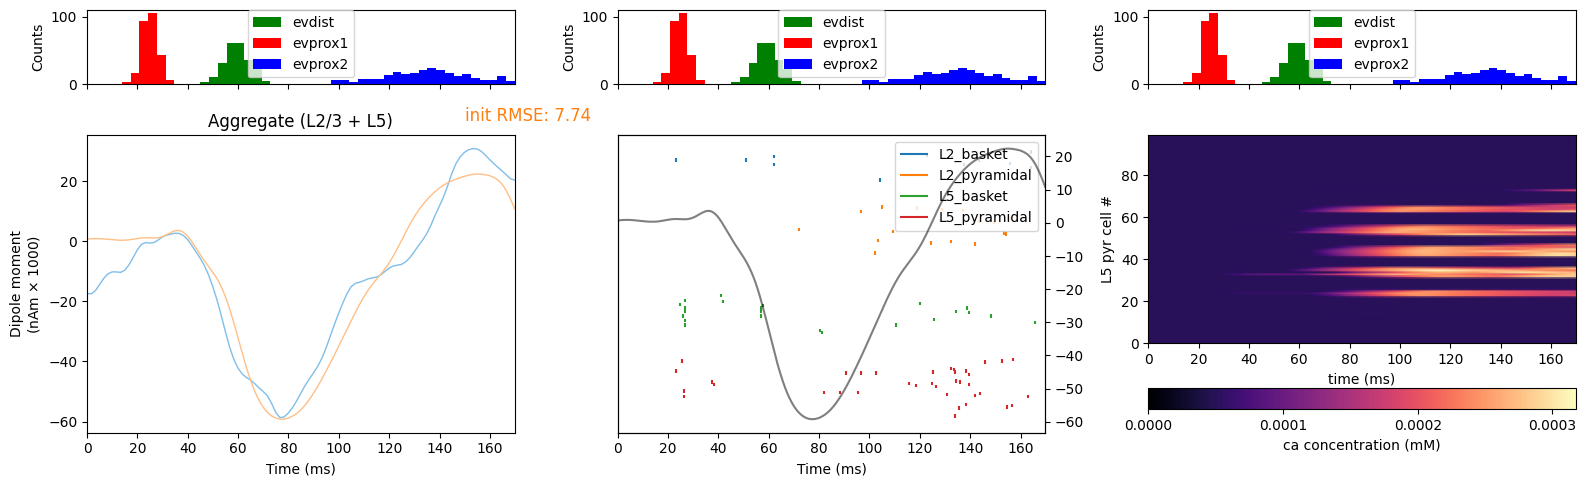

In [ ]:
fig, axes = plt.subplots(2,3,figsize=(16, 5), sharex=True, height_ratios=[0.25,1])

net_init_no.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_init_no.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_init_no.cell_response.plot_spikes_hist(ax=axes[0,2], spike_types=['prox1', 'evdist', 'prox2'], show=False)


no_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_no.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,40, f'init RMSE: {no_rmse_init:.2f}', fontsize=12, color='tab:orange')

net_init_no.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(init_no.times,init_no.data['agg'],color='k', alpha=0.5)

ca_map = axes[1,2].pcolormesh(net_init_no.cell_response.times, np.arange(100), no_l5_tuft, cmap='magma', shading='gouraud', vmin=0)
axes[1,2].set_ylabel('L5 pyr cell #')
axes[1,2].set_xlabel('time (ms)')
cb = plt.colorbar(ax=axes[1,2], mappable=ca_map, label='ca concentration (mM)', orientation='horizontal')
cb.set_ticks(np.arange(0,0.0004,0.0001))
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'no_dpl_init.png'))

#fig.savefig(os.path.join(pathfig,'no_dpl_init.svg'))

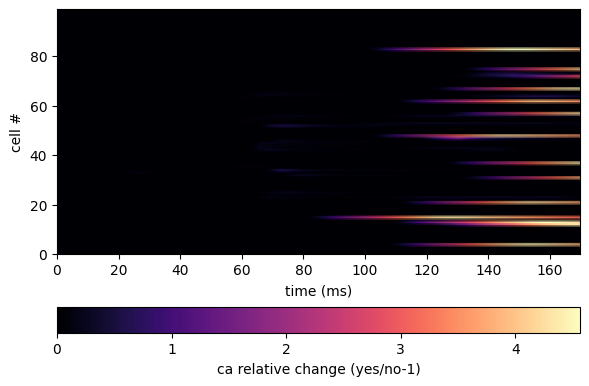

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
ca_map = ax.pcolormesh(net_init_no.cell_response.times, np.arange(100), yes_l5_tuft/no_l5_tuft-1, cmap='magma', shading='gouraud', vmin=0)

cb = plt.colorbar(ax=ax, mappable=ca_map, label='ca relative change (yes/no-1)', orientation='horizontal')
#cb.set_ticks(np.arange(0,0.0004,0.0001))
ax.set_ylabel('cell #')
ax.set_xlabel('time (ms)')
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'yes_vs_no.png'))

In [ ]:
def set_params(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
    
    net.add_evoked_drive('prox1',
                        mu=21,
                        sigma=6,
                        numspikes=1,
                        location='proximal',
                        weights_ampa={'L2_basket': 0.049215652055858136*0.01,
                                        'L2_pyramidal': 0.008739791084703059*0.1,
                                        'L5_basket': 0.07533928398974252,
                                        'L5_pyramidal': 0.43358890188330773*0.1},
                        weights_nmda={'L2_basket': 0.09377367973932317*0.01,
                                        'L2_pyramidal': 0.002633168778091414*0.1,
                                        'L5_basket': 0.015063099154731219,
                                        'L5_pyramidal': 0.019305264777853857*0.1},
                        synaptic_delays=synaptic_delays_p, event_seed=544)

    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

    net.add_evoked_drive('evdist',
                            mu=58.04965276608635,
                            sigma=3.414615128403157,
                            numspikes=1,
                            location='distal',
                            weights_ampa={'L2_basket': 0.0045165420596565906,
                                        'L2_pyramidal': 0.19298147034260757*0.05,
                                        'L5_pyramidal': 0.2919381063247272*0.1},
                            weights_nmda={'L2_basket': 0.0005606828245308956,
                                        'L2_pyramidal': 0.7736490894787733*0.05,
                                        'L5_pyramidal': 0.40907999439912374*0.05},
                            synaptic_delays=synaptic_delays_d, event_seed=544)

    weights_ampa_p2 = {'L2_basket':
                       params['prox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['prox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['prox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['prox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['prox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['prox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['prox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['prox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('prox2',
                        mu=130,
                        sigma=18,
                        numspikes=2,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

In [ ]:
constraints = dict({'prox2_nmda_L2_basket': (9e-5, 1e-2),
                'prox2_nmda_L2_pyramidal': (0.005, .5),
                'prox2_nmda_L5_basket': (2e-5, 4e-2),
                'prox2_nmda_L5_pyramidal': (0.005, .5),
                'prox2_ampa_L2_basket': (5e-5, 1e-1),
                'prox2_ampa_L2_pyramidal': (0.005, .5),
                'prox2_ampa_L5_basket': (2e-4, 1e-2),
                'prox2_ampa_L5_pyramidal': (0.005, .5)})

In [ ]:
# net_yes_optim = duecker_2025_ET_model()
# net_yes_optim = Optimizer(net_yes_optim, tstop=tstop, constraints=constraints,
#                   set_params=set_params, solver='bayesian', obj_fun='dipole_rmse', max_iter=200)

# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     net_yes_optim.fit(target=yes_dpl, scale_factor=scale_factor,
#               smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     yes_opt_dpl = simulate_dipole(net_yes_optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
# yes_opt_dpl.scale(scale_factor)
# yes_opt_dpl.smooth(smooth_window_len)

# fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# # plot original
# yes_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
# init_yes.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
# yes_opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
# axes[0].legend(['experimental', 'initial', 'optimized'])
# net_yes_optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

# fig1 = net_yes_optim.plot_convergence()


# with open('net_yes_optim.pkl', 'wb') as file:
#         pickle.dump(net_yes_optim.net_, file)

In [ ]:
yes_opt_rmse = _rmse(yes_dpl, yes_opt_dpl, tstart=0,tstop=1000)


NameError: name 'yes_opt_dpl' is not defined

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14, 5), sharex=True, height_ratios=[0.25,1])

net_yes_optim.net_.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_yes_optim.net_.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['prox1', 'evdist', 'prox2'], show=False)

# plot original
yes_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_yes.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,120, f'init RMSE: {yes_rmse_init:.2f}', fontsize=12, color='tab:orange')
yes_opt_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:green')
axes[1,0].text(150,100, f'opt RMSE: {yes_opt_rmse:.2f}', fontsize=12, color='tab:green')

net_yes_optim.net_.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(yes_opt_dpl.times,yes_opt_dpl.data['agg'],color='k', alpha=0.5)

fig.savefig(os.path.join(pathfig,'optim_yes_round1.png'))
fig.savefig(os.path.join(pathfig,'optim_yes_round1.svg'))

In [ ]:
prox2_weights_ampa = net_yes_optim.net_.external_drives['prox2']['weights_ampa']
prox2_weights_nmda = net_yes_optim.net_.external_drives['prox2']['weights_nmda']

dist_weights_ampa = net_yes_optim.net_.external_drives['evdist']['weights_ampa']
dist_weights_nmda = net_yes_optim.net_.external_drives['evdist']['weights_nmda']

prox1_weights_ampa = net_yes_optim.net_.external_drives['prox1']['weights_ampa']
prox1_weights_nmda = net_yes_optim.net_.external_drives['prox1']['weights_nmda']

In [ ]:
def set_params_time(net, params):

    # Proximal 1
    
    net.add_evoked_drive('prox1',
                         mu=params['prox1_mu'],
                         sigma=params['prox1_sigma'],
                         numspikes=1,
                         location='proximal',
                         weights_ampa=prox1_weights_ampa,
                         weights_nmda=prox1_weights_nmda,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    
    net.add_evoked_drive('evdist',
                         mu=params['evdist_mu'],
                         sigma=params['evdist_sigma'],
                         numspikes=int(np.round(params['evdist_num_spikes'])),
                         location='distal',
                         weights_ampa=dist_weights_ampa,
                         weights_nmda=dist_weights_nmda,
                         synaptic_delays=synaptic_delays_d, event_seed=544)
    
    net.add_evoked_drive('prox2',
                        mu=params['prox2_mu'],
                        sigma=params['prox2_sigma'],
                        numspikes=int(np.round(params['prox2_num_spikes'])),
                        location='proximal',
                        weights_ampa=prox2_weights_ampa,
                        weights_nmda=prox2_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay


constraints = dict({'prox1_mu': (16, 21),
                'prox1_sigma': (2., 4),

                'evdist_mu': (57, 62),
                'evdist_sigma': (2, 3),
                'evdist_num_spikes': (1, 2),

                'prox2_mu': (105, 135),
                'prox2_sigma': (8, 12),
                'prox2_num_spikes': (1, 4)})

In [ ]:
net_yes_optim_time = duecker_2025_ET_model()
net_yes_optim_time = Optimizer(net_yes_optim_time, tstop=tstop, constraints=constraints,
                  set_params=set_params_time, solver='bayesian', obj_fun='dipole_rmse', max_iter=500)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    net_yes_optim_time.fit(target=yes_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    yes_opt_dpl_time = simulate_dipole(net_yes_optim_time.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
yes_opt_dpl_time.scale(scale_factor)
yes_opt_dpl_time.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
yes_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
yes_opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
yes_opt_dpl_time.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
net_yes_optim_time.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = net_yes_optim.plot_convergence()

In [ ]:
yes_opt_rmse_time = _rmse(yes_opt_dpl_time, yes_opt_dpl, tstart=0,tstop=1000)


In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14, 5), sharex=True, height_ratios=[0.25,1])

net_yes_optim.net_.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['prox1', 'evdist', 'prox2'], show=False)
net_yes_optim.net_.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['prox1', 'evdist', 'prox2'], show=False)

# plot original
yes_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_yes.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,120, f'init RMSE: {yes_rmse_init:.2f}', fontsize=12, color='tab:orange')
yes_opt_dpl_time.plot(ax=axes[1,0], layer='agg', show=False, color='tab:green')
axes[1,0].text(150,100, f'opt RMSE: {yes_opt_rmse_time:.2f}', fontsize=12, color='tab:green')

net_yes_optim.net_.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(yes_opt_dpl_time.times,yes_opt_dpl_time.data['agg'],color='k', alpha=0.5)

fig.savefig(os.path.join(pathfig,'optim_yes_round2.png'))
fig.savefig(os.path.join(pathfig,'optim_yes_round2.svg'))